# Experiment 12: Project RESCUE-SWARM
## Cooperative Multi-Agent Reinforcement Learning

**Aim:** To develop a multi-agent reinforcement learning system in which rescue agents learn to coordinate their actions in a disaster environment.

## Exercise 1: Environment Design
Create a grid-based environment with multiple rescue agents, victims, obstacles, and hazardous areas.

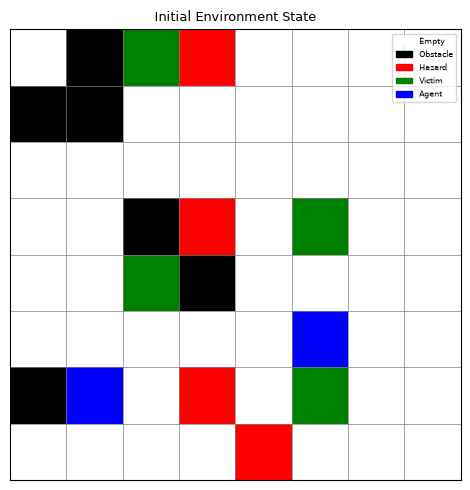

Grid size : 8x8
Agents    : 2
Victims   : 4
Obstacles : 6
Hazards   : 4


In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings('ignore')

# Cell types
EMPTY    = 0
OBSTACLE = 1
HAZARD   = 2
VICTIM   = 3
AGENT    = 4

CELL_COLORS = {
    EMPTY:    'white',
    OBSTACLE: 'black',
    HAZARD:   'red',
    VICTIM:   'green',
    AGENT:    'blue',
}

class RescueEnvironment:
    """Grid-based disaster rescue environment."""

    def __init__(self, grid_size=8, n_agents=2, n_victims=4,
                 n_obstacles=6, n_hazards=4, seed=42):
        self.grid_size  = grid_size
        self.n_agents   = n_agents
        self.n_victims  = n_victims
        self.n_obstacles = n_obstacles
        self.n_hazards  = n_hazards
        self.seed       = seed
        self.reset()

    # ------------------------------------------------------------------ #
    def _random_empty_cell(self, rng, occupied):
        while True:
            r = rng.randint(0, self.grid_size - 1)
            c = rng.randint(0, self.grid_size - 1)
            if (r, c) not in occupied:
                occupied.add((r, c))
                return (r, c)

    def reset(self):
        rng = random.Random(self.seed)
        self.grid = np.zeros((self.grid_size, self.grid_size), dtype=int)
        occupied = set()

        # Place obstacles
        self.obstacle_cells = set()
        for _ in range(self.n_obstacles):
            pos = self._random_empty_cell(rng, occupied)
            self.grid[pos] = OBSTACLE
            self.obstacle_cells.add(pos)

        # Place hazards
        self.hazard_cells = set()
        for _ in range(self.n_hazards):
            pos = self._random_empty_cell(rng, occupied)
            self.grid[pos] = HAZARD
            self.hazard_cells.add(pos)

        # Place victims
        self.victim_cells = set()
        for _ in range(self.n_victims):
            pos = self._random_empty_cell(rng, occupied)
            self.grid[pos] = VICTIM
            self.victim_cells.add(pos)

        # Place agents
        self.agent_positions = []
        for _ in range(self.n_agents):
            pos = self._random_empty_cell(rng, occupied)
            self.agent_positions.append(list(pos))

        self.rescued = 0
        self.steps   = 0
        return self._get_states()

    # ------------------------------------------------------------------ #
    def _get_states(self):
        """Return a tuple state per agent: (row, col, victims_remaining)."""
        victims_left = len(self.victim_cells)
        return [tuple(pos) + (victims_left,) for pos in self.agent_positions]

    # ------------------------------------------------------------------ #
    def step(self, actions):
        """
        actions: list of ints, one per agent (0=Up,1=Down,2=Left,3=Right,4=Stay)
        Returns: states, rewards, done, info
        """
        MOVES = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1), 4: (0, 0)}
        rewards  = [0.0] * self.n_agents
        new_positions = []

        for i, (pos, action) in enumerate(zip(self.agent_positions, actions)):
            dr, dc = MOVES[action]
            nr, nc = pos[0] + dr, pos[1] + dc

            # Boundary / obstacle check
            if (0 <= nr < self.grid_size and
                0 <= nc < self.grid_size and
                (nr, nc) not in self.obstacle_cells):
                new_pos = [nr, nc]
            else:
                new_pos = list(pos)          # stay; penalty for hitting wall
                rewards[i] -= 0.5

            new_positions.append(new_pos)

        # Collision check between agents
        for i in range(self.n_agents):
            for j in range(i + 1, self.n_agents):
                if new_positions[i] == new_positions[j]:
                    rewards[i] -= 1.0
                    rewards[j] -= 1.0
                    new_positions[j] = list(self.agent_positions[j])  # revert j

        self.agent_positions = new_positions

        # Evaluate new positions
        for i, pos in enumerate(self.agent_positions):
            cell = tuple(pos)
            if cell in self.hazard_cells:
                rewards[i] -= 2.0                      # hazard penalty
            elif cell in self.victim_cells:
                rewards[i] += 10.0                     # rescue reward
                self.victim_cells.discard(cell)
                self.rescued += 1
            else:
                rewards[i] -= 0.1                      # step cost

        self.steps += 1
        done = (len(self.victim_cells) == 0) or (self.steps >= 200)
        return self._get_states(), rewards, done, {'rescued': self.rescued}

    # ------------------------------------------------------------------ #
    def render(self, ax=None, title=''):
        show = ax is None
        if show:
            fig, ax = plt.subplots(figsize=(5, 5))

        display = self.grid.copy().astype(float)
        for pos in self.victim_cells:
            display[pos] = VICTIM
        for pos in self.agent_positions:
            display[tuple(pos)] = AGENT

        cmap = ListedColormap([CELL_COLORS[k] for k in range(5)])
        ax.imshow(display, cmap=cmap, vmin=0, vmax=4)
        ax.set_xticks(np.arange(-0.5, self.grid_size, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, self.grid_size, 1), minor=True)
        ax.grid(which='minor', color='gray', linewidth=0.5)
        ax.tick_params(which='both', bottom=False, left=False,
                       labelbottom=False, labelleft=False)
        legend = [
            mpatches.Patch(color='white',  label='Empty',    edgecolor='gray'),
            mpatches.Patch(color='black',  label='Obstacle'),
            mpatches.Patch(color='red',    label='Hazard'),
            mpatches.Patch(color='green',  label='Victim'),
            mpatches.Patch(color='blue',   label='Agent'),
        ]
        ax.legend(handles=legend, loc='upper right',
                  fontsize=6, framealpha=0.8)
        ax.set_title(title, fontsize=9)
        if show:
            plt.tight_layout()
            plt.show()

# ---- Show initial environment ----
env = RescueEnvironment()
env.reset()
env.render(title='Initial Environment State')
print(f"Grid size : {env.grid_size}x{env.grid_size}")
print(f"Agents    : {env.n_agents}")
print(f"Victims   : {env.n_victims}")
print(f"Obstacles : {env.n_obstacles}")
print(f"Hazards   : {env.n_hazards}")


## Exercise 2: States, Actions, and Rewards

| Element | Description |
|---------|-------------|
| **State** | `(row, col, victims_remaining)` per agent |
| **Actions** | 0=Up, 1=Down, 2=Left, 3=Right, 4=Stay |
| **Rewards** | +10 rescue · −2 hazard · −1 collision · −0.5 wall · −0.1 step |

In [2]:
ACTIONS = {0: 'Up', 1: 'Down', 2: 'Left', 3: 'Right', 4: 'Stay'}
N_ACTIONS = len(ACTIONS)

print("=== State Space ===")
print("State per agent: (row, col, victims_remaining)")
env_temp = RescueEnvironment()
states = env_temp.reset()
for i, s in enumerate(states):
    print(f"  Agent {i}: {s}")

print("\n=== Action Space ===")
for k, v in ACTIONS.items():
    print(f"  Action {k}: {v}")

print("\n=== Reward Structure ===")
rewards_info = [
    ("+10.0", "Successful rescue"),
    ("-2.0",  "Entering hazardous area"),
    ("-1.0",  "Agent-agent collision"),
    ("-0.5",  "Hitting wall / obstacle"),
    ("-0.1",  "Normal step cost"),
]
for val, desc in rewards_info:
    print(f"  {val:>6}  {desc}")


=== State Space ===
State per agent: (row, col, victims_remaining)
  Agent 0: (6, 1, 4)
  Agent 1: (5, 5, 4)

=== Action Space ===
  Action 0: Up
  Action 1: Down
  Action 2: Left
  Action 3: Right
  Action 4: Stay

=== Reward Structure ===
   +10.0  Successful rescue
    -2.0  Entering hazardous area
    -1.0  Agent-agent collision
    -0.5  Hitting wall / obstacle
    -0.1  Normal step cost


## Exercise 3: Independent Q-Learning
Each agent maintains its own Q-table and learns without coordinating with others.

In [3]:
class QLearningAgent:
    """Independent Q-Learning agent."""

    def __init__(self, agent_id, n_actions=5,
                 alpha=0.1, gamma=0.9,
                 epsilon=1.0, epsilon_min=0.05, epsilon_decay=0.995):
        self.agent_id     = agent_id
        self.n_actions    = n_actions
        self.alpha        = alpha
        self.gamma        = gamma
        self.epsilon      = epsilon
        self.epsilon_min  = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.q_table      = {}

    def _get_q(self, state):
        if state not in self.q_table:
            self.q_table[state] = np.zeros(self.n_actions)
        return self.q_table[state]

    def choose_action(self, state):
        if random.random() < self.epsilon:
            return random.randint(0, self.n_actions - 1)
        return int(np.argmax(self._get_q(state)))

    def update(self, state, action, reward, next_state):
        q_cur  = self._get_q(state)
        q_next = self._get_q(next_state)
        td     = reward + self.gamma * np.max(q_next) - q_cur[action]
        q_cur[action] += self.alpha * td

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min,
                           self.epsilon * self.epsilon_decay)


def run_independent(n_episodes=500, seed=42):
    env     = RescueEnvironment(seed=seed)
    agents  = [QLearningAgent(i) for i in range(env.n_agents)]

    ep_rewards   = []
    ep_rescued   = []
    ep_steps     = []
    ep_collisions = []

    for ep in range(n_episodes):
        env.seed = seed + ep
        states   = env.reset()
        total_r  = np.zeros(env.n_agents)
        collisions = 0
        done     = False

        while not done:
            actions = [a.choose_action(s) for a, s in zip(agents, states)]
            next_states, rewards, done, info = env.step(actions)

            for i, agent in enumerate(agents):
                agent.update(states[i], actions[i], rewards[i], next_states[i])
            
            # Count collisions (reward penalty == -1 or less from collision)
            for r in rewards:
                if r <= -1.0:
                    collisions += 1

            total_r += np.array(rewards)
            states   = next_states

        for agent in agents:
            agent.decay_epsilon()

        ep_rewards.append(total_r.sum())
        ep_rescued.append(info['rescued'])
        ep_steps.append(env.steps)
        ep_collisions.append(collisions)

    return {
        'rewards':    ep_rewards,
        'rescued':    ep_rescued,
        'steps':      ep_steps,
        'collisions': ep_collisions,
        'agents':     agents,
    }

print("Training Independent Q-Learning agents ...")
ind_results = run_independent(n_episodes=500)
print(f"Done. Final 50-ep avg rescue: {np.mean(ind_results['rescued'][-50:]):.2f}")


Training Independent Q-Learning agents ...
Done. Final 50-ep avg rescue: 2.22


## Exercise 4: Cooperative Learning
Agents share a **common reward** (sum of all individual rewards) so they are collectively incentivised to maximise team performance. Each agent still has its own Q-table (decentralised execution, centralised reward signal).

In [4]:
def run_cooperative(n_episodes=500, seed=42):
    env     = RescueEnvironment(seed=seed)
    agents  = [QLearningAgent(i) for i in range(env.n_agents)]

    ep_rewards    = []
    ep_rescued    = []
    ep_steps      = []
    ep_collisions = []

    for ep in range(n_episodes):
        env.seed = seed + ep
        states   = env.reset()
        total_r  = 0.0
        collisions = 0
        done     = False

        while not done:
            actions = [a.choose_action(s) for a, s in zip(agents, states)]
            next_states, rewards, done, info = env.step(actions)

            shared_reward = sum(rewards)           # cooperative: common reward

            for i, agent in enumerate(agents):
                agent.update(states[i], actions[i], shared_reward, next_states[i])

            for r in rewards:
                if r <= -1.0:
                    collisions += 1

            total_r += shared_reward
            states   = next_states

        for agent in agents:
            agent.decay_epsilon()

        ep_rewards.append(total_r)
        ep_rescued.append(info['rescued'])
        ep_steps.append(env.steps)
        ep_collisions.append(collisions)

    return {
        'rewards':    ep_rewards,
        'rescued':    ep_rescued,
        'steps':      ep_steps,
        'collisions': ep_collisions,
        'agents':     agents,
    }

print("Training Cooperative Q-Learning agents ...")
coop_results = run_cooperative(n_episodes=500)
print(f"Done. Final 50-ep avg rescue: {np.mean(coop_results['rescued'][-50:]):.2f}")


Training Cooperative Q-Learning agents ...
Done. Final 50-ep avg rescue: 2.38


## Exercise 5: Visualization
### 5a — Agent Movements in a Trained Episode

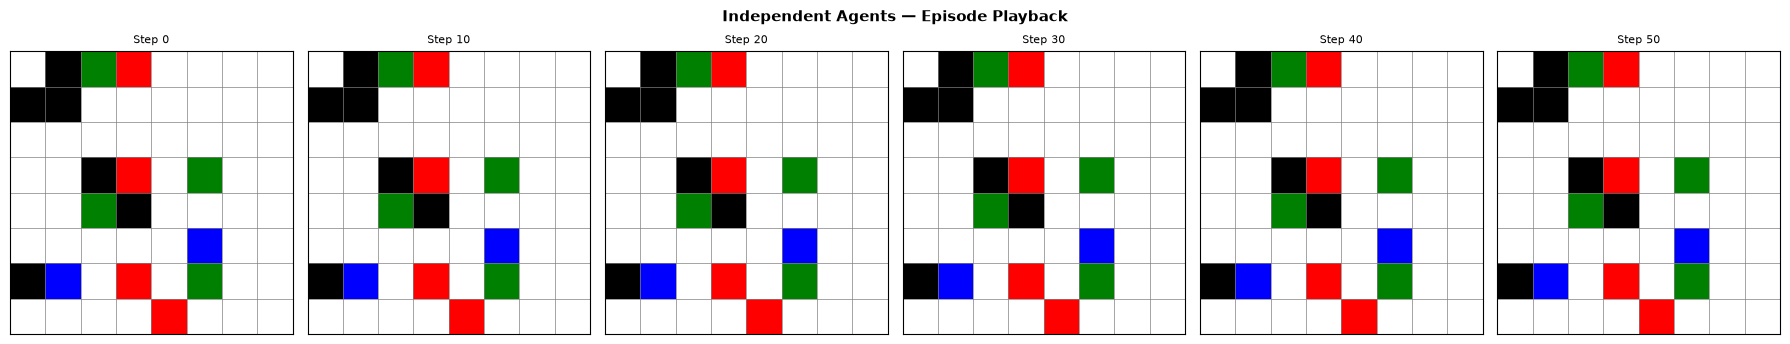

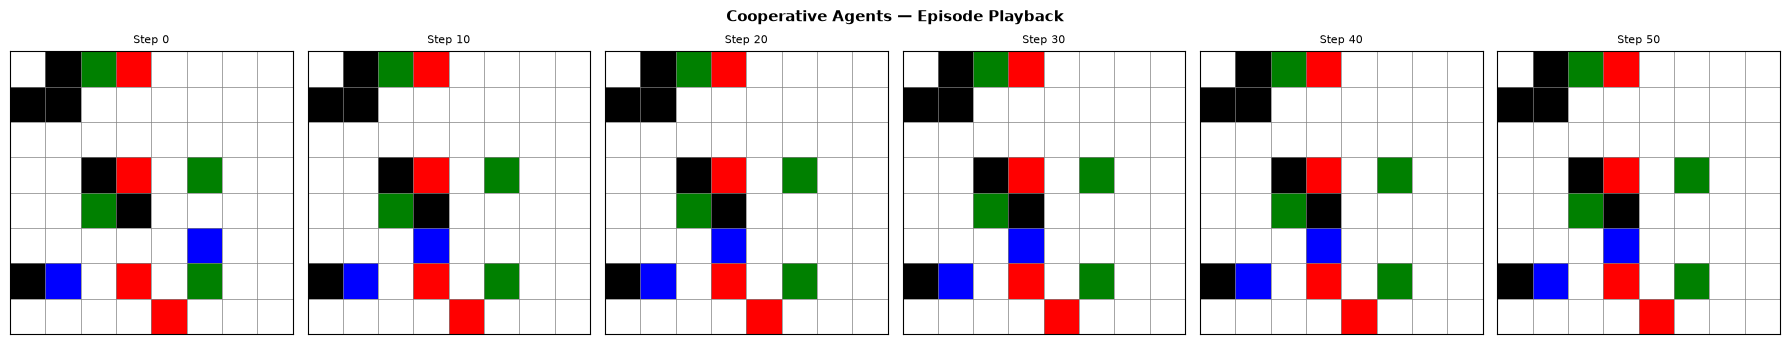

In [5]:
def visualize_episode(agents, title='Episode Visualization', seed=42, max_steps=50):
    """Run one episode with trained agents and snapshot 6 frames."""
    env = RescueEnvironment(seed=seed)
    env.seed = seed
    states = env.reset()

    snapshots = [env.grid.copy()]
    snap_positions = [list(map(list, env.agent_positions))]
    snap_victims   = [set(env.victim_cells)]
    snap_steps     = [0]
    done = False

    while not done and env.steps < max_steps:
        actions = [a.choose_action(s) for a, s in zip(agents, states)]
        # exploit only
        for a in agents:
            a.epsilon = 0.0
        states, _, done, _ = env.step(actions)
        if env.steps % (max_steps // 5) == 0 or done:
            snapshots.append(env.grid.copy())
            snap_positions.append(list(map(list, env.agent_positions)))
            snap_victims.append(set(env.victim_cells))
            snap_steps.append(env.steps)

    n = min(6, len(snapshots))
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
    if n == 1:
        axes = [axes]

    for idx in range(n):
        ax = axes[idx]
        display = snapshots[idx].astype(float)
        for pos in snap_victims[idx]:
            display[pos] = VICTIM
        for pos in snap_positions[idx]:
            display[tuple(pos)] = AGENT

        cmap = ListedColormap([CELL_COLORS[k] for k in range(5)])
        ax.imshow(display, cmap=cmap, vmin=0, vmax=4)
        ax.set_xticks(np.arange(-0.5, env.grid_size, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, env.grid_size, 1), minor=True)
        ax.grid(which='minor', color='gray', linewidth=0.5)
        ax.tick_params(which='both', bottom=False, left=False,
                       labelbottom=False, labelleft=False)
        ax.set_title(f'Step {snap_steps[idx]}', fontsize=8)

    fig.suptitle(title, fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

visualize_episode(ind_results['agents'],  title='Independent Agents — Episode Playback')
visualize_episode(coop_results['agents'], title='Cooperative Agents — Episode Playback')


### 5b — Learning Curves

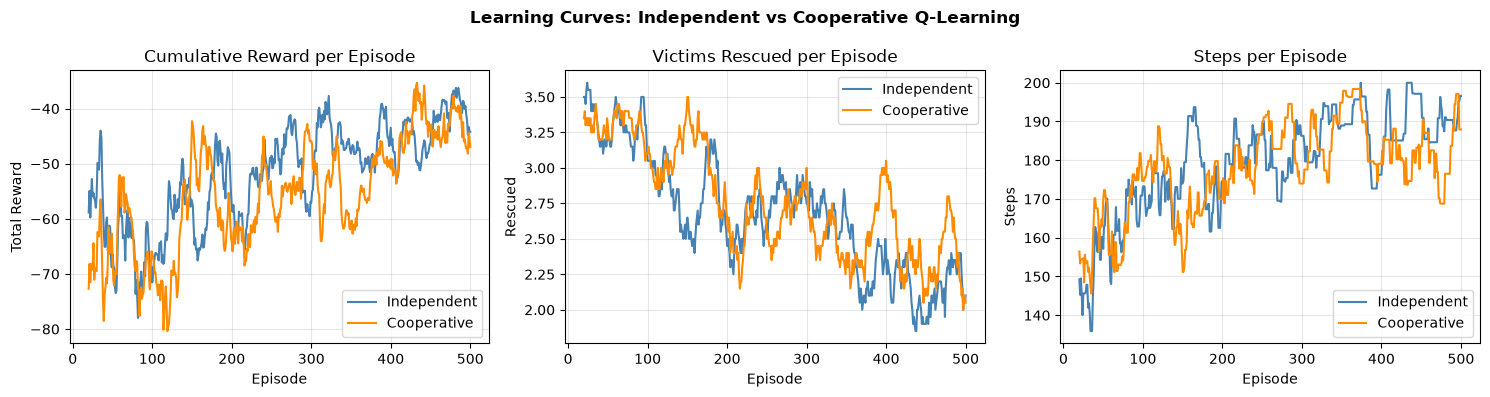

In [6]:
def smooth(data, window=20):
    return np.convolve(data, np.ones(window) / window, mode='valid')

episodes = np.arange(1, 501)
w = 20  # smoothing window
x_smooth = episodes[w - 1:]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Cumulative rewards
axes[0].plot(x_smooth, smooth(ind_results['rewards']),  label='Independent', color='steelblue')
axes[0].plot(x_smooth, smooth(coop_results['rewards']), label='Cooperative',  color='darkorange')
axes[0].set_title('Cumulative Reward per Episode')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Total Reward')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Victims rescued
axes[1].plot(x_smooth, smooth(ind_results['rescued']),  label='Independent', color='steelblue')
axes[1].plot(x_smooth, smooth(coop_results['rescued']), label='Cooperative',  color='darkorange')
axes[1].set_title('Victims Rescued per Episode')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Rescued')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Steps per episode
axes[2].plot(x_smooth, smooth(ind_results['steps']),  label='Independent', color='steelblue')
axes[2].plot(x_smooth, smooth(coop_results['steps']), label='Cooperative',  color='darkorange')
axes[2].set_title('Steps per Episode')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Steps')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('Learning Curves: Independent vs Cooperative Q-Learning',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## Exercise 6: Performance Evaluation
Comparison of Independent vs Cooperative approaches over the last 50 episodes.

In [7]:
N = 50  # evaluation window

metrics = {
    'Metric': [
        'Avg Victims Rescued',
        'Avg Completion Steps',
        'Avg Cumulative Reward',
        'Avg Collisions / Episode',
        'Rescue Rate (%)',
    ],
    'Independent': [
        f"{np.mean(ind_results['rescued'][-N:]):.2f}",
        f"{np.mean(ind_results['steps'][-N:]):.1f}",
        f"{np.mean(ind_results['rewards'][-N:]):.2f}",
        f"{np.mean(ind_results['collisions'][-N:]):.2f}",
        f"{100 * np.mean(ind_results['rescued'][-N:]) / env.n_victims:.1f}%",
    ],
    'Cooperative': [
        f"{np.mean(coop_results['rescued'][-N:]):.2f}",
        f"{np.mean(coop_results['steps'][-N:]):.1f}",
        f"{np.mean(coop_results['rewards'][-N:]):.2f}",
        f"{np.mean(coop_results['collisions'][-N:]):.2f}",
        f"{100 * np.mean(coop_results['rescued'][-N:]) / env.n_victims:.1f}%",
    ],
}

header = f"{'Metric':<30} {'Independent':>15} {'Cooperative':>15}"
print(header)
print('-' * len(header))
for i in range(len(metrics['Metric'])):
    print(f"{metrics['Metric'][i]:<30} {metrics['Independent'][i]:>15} {metrics['Cooperative'][i]:>15}")


Metric                             Independent     Cooperative
--------------------------------------------------------------
Avg Victims Rescued                       2.22            2.38
Avg Completion Steps                     188.9           181.3
Avg Cumulative Reward                   -39.41          -42.79
Avg Collisions / Episode                  8.76           10.90
Rescue Rate (%)                          55.5%           59.5%


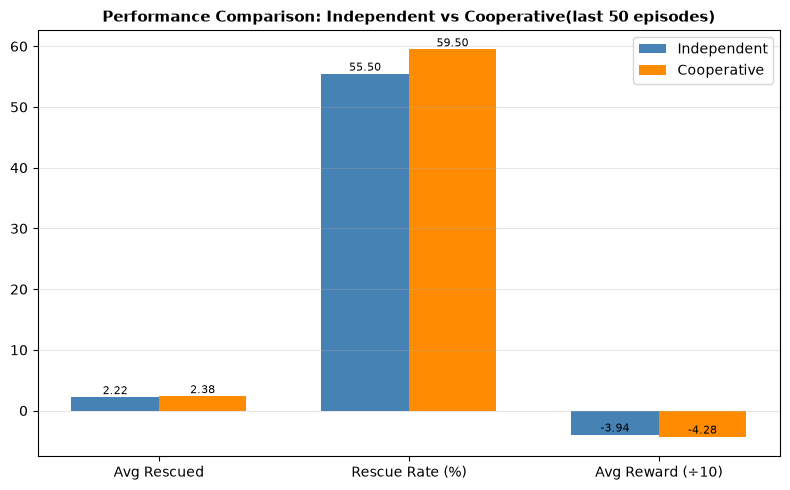


Note: 'Avg Reward (÷10)' is scaled by 1/10 for display.


In [9]:
# Bar chart comparison
labels = ['Avg Rescued', 'Rescue Rate (%)', 'Avg Reward (÷10)']
ind_vals  = [
    np.mean(ind_results['rescued'][-N:]),
    100 * np.mean(ind_results['rescued'][-N:]) / env.n_victims,
    np.mean(ind_results['rewards'][-N:])  / 10,
]
coop_vals = [
    np.mean(coop_results['rescued'][-N:]),
    100 * np.mean(coop_results['rescued'][-N:]) / env.n_victims,
    np.mean(coop_results['rewards'][-N:]) / 10,
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, ind_vals,  width, label='Independent', color='steelblue')
bars2 = ax.bar(x + width/2, coop_vals, width, label='Cooperative',  color='darkorange')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title('Performance Comparison: Independent vs Cooperative(last 50 episodes)',
             fontsize=11, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()
print("\nNote: 'Avg Reward (÷10)' is scaled by 1/10 for display.")
